In [1]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from pypalettes import load_cmap


In [2]:
current_path = Path.cwd()
project_root = next(
    (
        path
        for path in (current_path, *current_path.parents)
        if (path / "data" / "raw" / "listings.csv").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing data/raw/listings.csv")

df = pd.read_csv(project_root / "data" / "raw" / "listings.csv")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

sys.path.append(str(project_root))   
from src.cleaning import basic_clean

cmap = load_cmap('CarolMan')


['host_is_superhost', 'neighbourhood_cleansed', 'is_house', 'accommodates', 'bedrooms', 'price', 'minimum_nights', 'bathrooms', 'has_rating', 'weighted_rating', 'log_price', 'minimum_nights_log', 'neighbourhood_grouped', 'dummy_Bjerke', 'dummy_Frogner', 'dummy_Gamle_Oslo', 'dummy_Grünerløkka', 'dummy_Nordre_Aker', 'dummy_Nordstrand', 'dummy_Sagene', 'dummy_St._Hanshaugen', 'dummy_Stovner/Grorud/Alna', 'dummy_Søndre_Nordstrand', 'dummy_Ullern', 'dummy_Vestre_Aker', 'dummy_Østensjø']


In [3]:
#doing the basic clean to look at relationships between variables for listing we will actually use
df_c = basic_clean(df)

columns = pd.DataFrame({
    "Column": df_c.columns,
    "Data type": df_c.dtypes.astype(str).values,
    "Unique values": df_c.nunique(dropna=True).values,
    "NaN values": df_c.isna().sum().values,
    })

print(columns)

                    Column        Data type  Unique values  NaN values
0   neighbourhood_cleansed              str             17           0
1                 latitude          float64           6028           0
2                longitude          float64           6550           0
3                 is_house            int64              2           0
4             accommodates            int64             16           0
5                 bedrooms          float64              8           0
6                     beds          float64             12         149
7          price_per_night          float64           4376           0
8                bathrooms          float64              8           0
9                 n_nights            int64             25           0
10        days_til_checkin  timedelta64[us]             25           0
11           checkin_month            int32             12           0


### Price
log price gives a more symmetric distribution and weights the more expensive listings less, good for linear regression

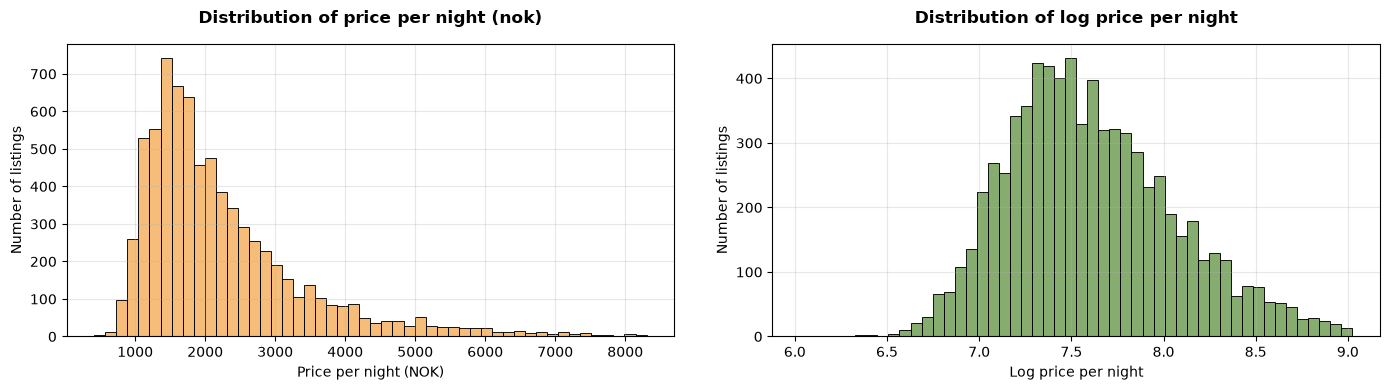

In [41]:
df_c['log_price'] = np.log(df_c['price_per_night'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plots = [('price_per_night', 'Price per night (NOK)'),
         ('log_price', 'Log price per night')]

for i, (ax, (var, label)) in enumerate(zip(axes, plots)):
    sns.histplot(data=df_c, x=var, bins=50, color=cmap(i+1), alpha=0.7, ax=ax)
    ax.set_title(f'Distribution of {label.lower()}', weight='bold', pad=15)
    ax.set_xlabel(label)
    ax.set_ylabel('Number of listings')
    ax.grid(alpha=0.3)

plt.tight_layout(w_pad=3)
plt.show()


### Location latitude and longitude
Not surrisingly, the more expensive regions aree near the city centre, however when we look by property type we see that it is to some extent because there are more houses there
not sure if it is needed for the models as it provides similiar information as neighbourhoods

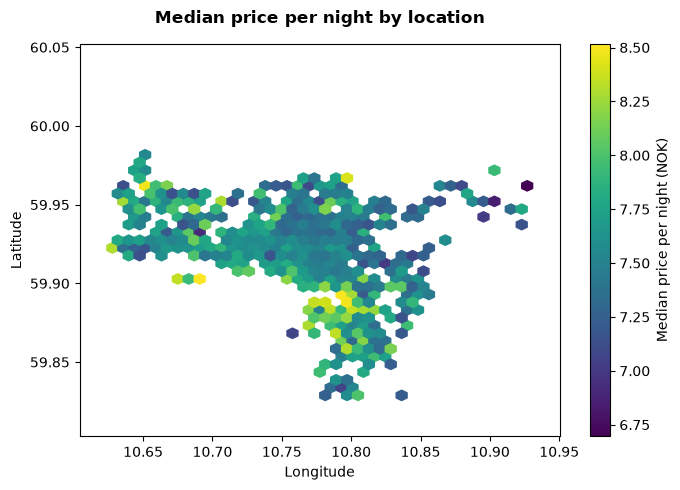

In [40]:
#looking a location in terms of lattitude and longitude
fig, ax = plt.subplots(figsize=(7, 5))

hb = ax.hexbin(df_c['longitude'], df_c['latitude'], C=df_c['log_price'],
               reduce_C_function=np.median,   # median price in each hexagon
               gridsize=40,                   # higher = smaller hexagons
               mincnt=3,                      # only show hexagons with at least 3 listings
               cmap='viridis')

fig.colorbar(hb, ax=ax, label='Median price per night (NOK)')
ax.set_title('Median price per night by location', weight='bold', pad=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()


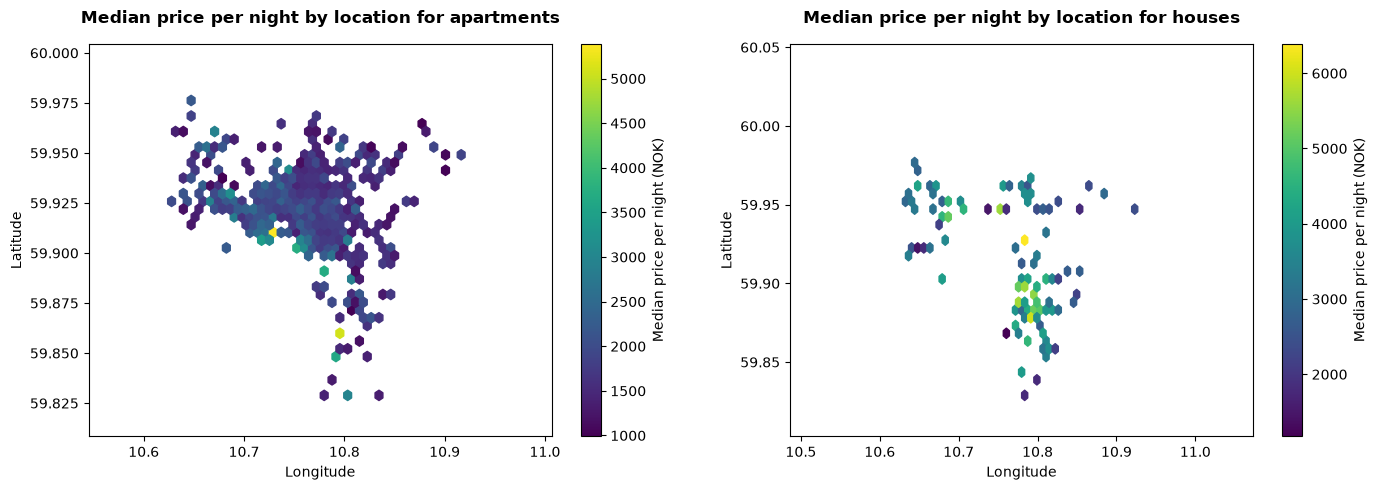

In [5]:
#diving by is house and is not house to see the effect on the map
labels = {0: 'apartments', 1: 'houses'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range(2):
    subset = df_c[df_c['is_house'] == i]
    ax = axes[i]
    hb = ax.hexbin(subset['longitude'], subset['latitude'], C=subset['price_per_night'],
                   reduce_C_function=np.median,
                   gridsize=40,
                   mincnt=3,
                   cmap='viridis')
    fig.colorbar(hb, ax=ax, label='Median price per night (NOK)')
    ax.set_aspect(1 / np.cos(np.radians(df_c['latitude'].mean())), adjustable='datalim')
    ax.set_title(f'Median price per night by location for {labels[i]}', weight='bold', pad=15)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
plt.tight_layout(w_pad=3)

### Neighbourhood 
we can see that some neighbourhoods are generally more expensive<br>
if we do one city model and one distric model we would have to group together some neighbourhoods since they have to few listings <br>
marka might have to be dropped considering it is a really different terrain than the other districts so it cannot be merged <br>
need to make dummies for linear regression

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


neighbourhood_cleansed
Grünerløkka          1417
Gamle Oslo           1280
Frogner              1115
St. Hanshaugen        870
Sagene                794
Nordstrand            348
Nordre Aker           282
Vestre Aker           248
Ullern                228
Østensjø              189
Bjerke                184
Sentrum               138
Alna                  116
Søndre Nordstrand      83
Grorud                 43
Stovner                30
Marka                  28
Name: count, dtype: int64


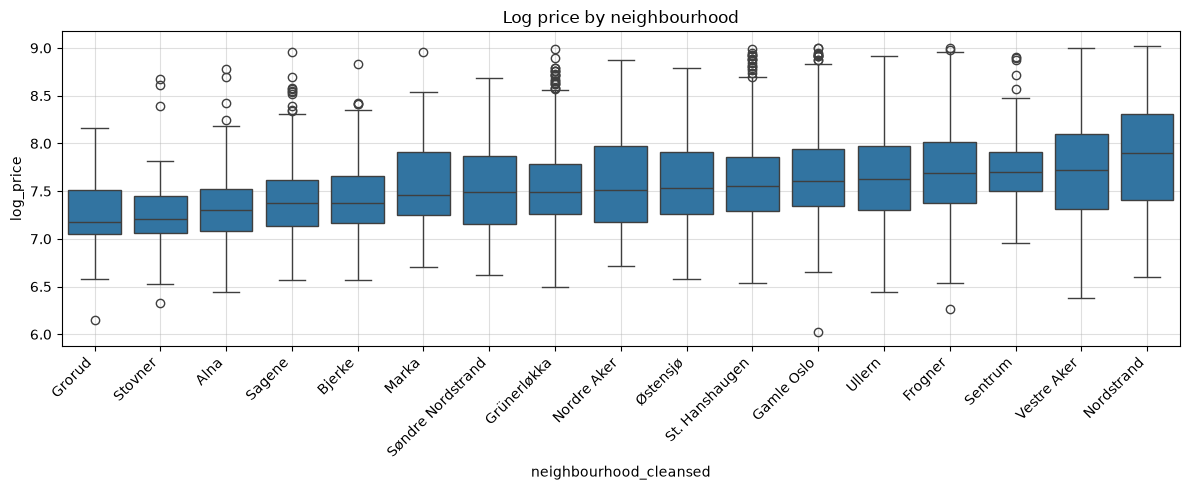

In [42]:
order = df_c.groupby("neighbourhood_cleansed")["log_price"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_c, x="neighbourhood_cleansed", y="log_price", order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Log price by neighbourhood")
plt.tight_layout()
plt.grid(alpha = 0.4)

print(df_c["neighbourhood_cleansed"].value_counts())   # check group sizes

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


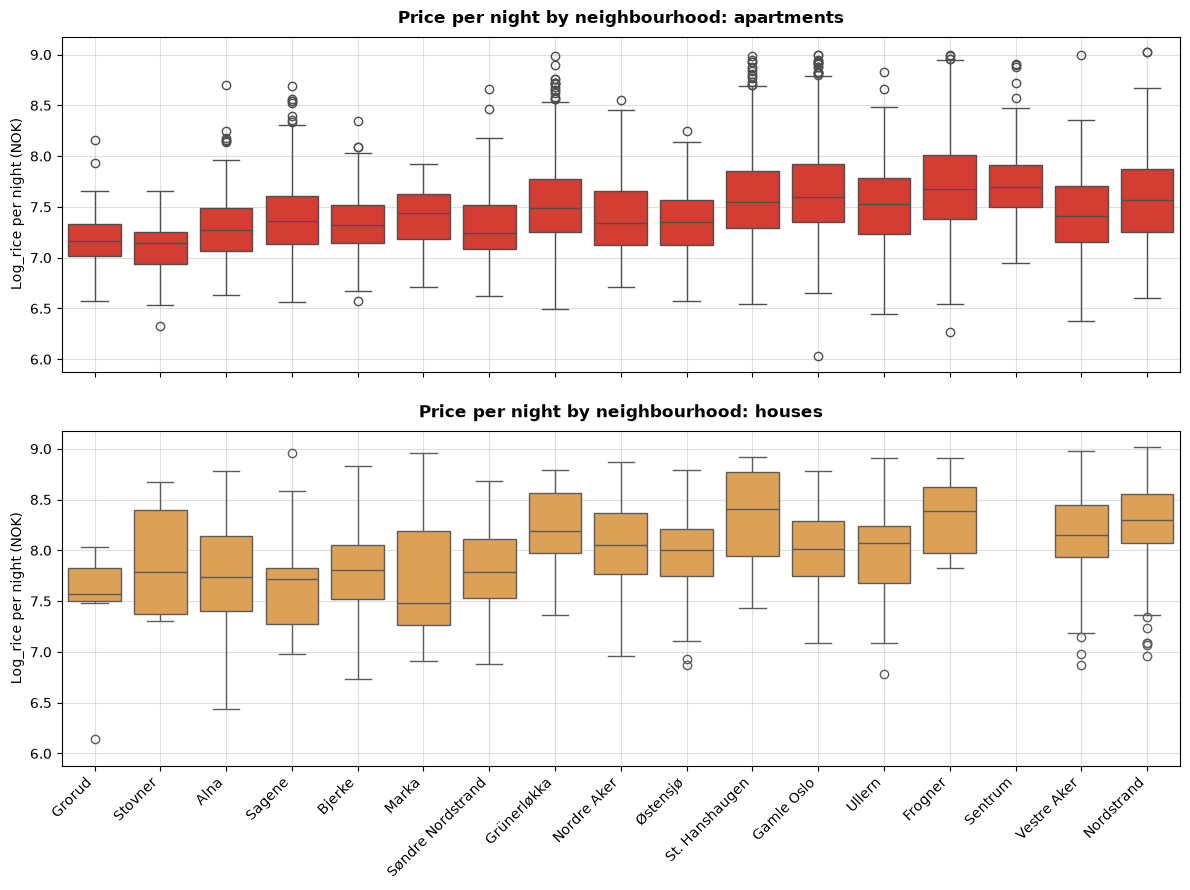

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)

for i, ax in enumerate(axes):
    subset = df_c[df_c['is_house'] == i]
    sns.boxplot(data=subset, x="neighbourhood_cleansed", y="log_price",
                order=order, color=cmap(i), showfliers=True, ax=ax)
    ax.set_title(f"Price per night by neighbourhood: {labels[i].lower()}", weight='bold', pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Log_rice per night (NOK)")
    ax.grid(alpha=0.4)

axes[1].tick_params(axis='x', labelrotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
plt.tight_layout(h_pad= 2)
plt.show()

### Property details
we see that bedrooms differentiates prices per night within the same value for accomodates, something beds does not do, therefore drop beds from dataframe for modelleing

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


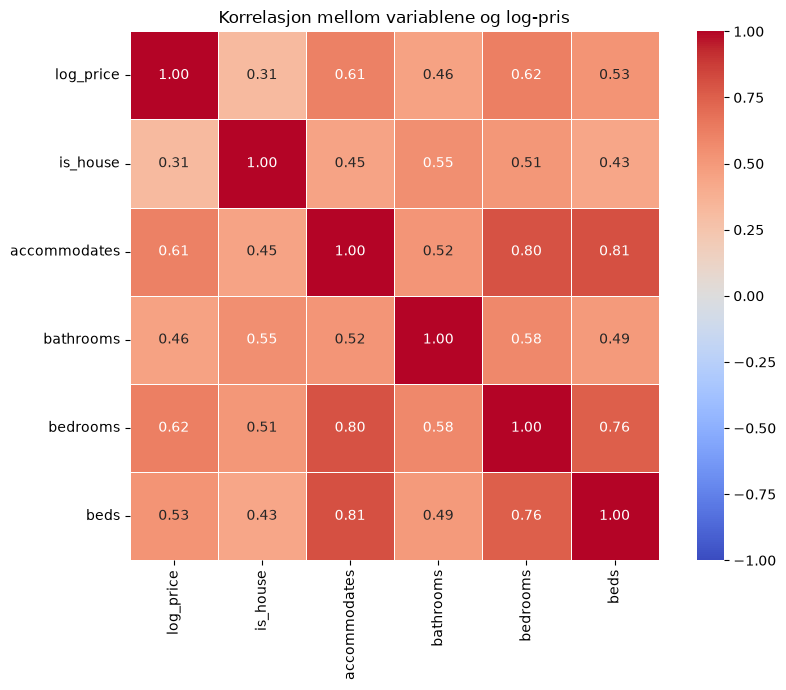

In [46]:
heatmap_columns = [
    'log_price', 'is_house', 'accommodates', 'bathrooms',
    'bedrooms', 'beds'
]

correlation_matrix = df_c[heatmap_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    square=True,
)
plt.title("Korrelasjon mellom variablene og log-pris")
plt.tight_layout()
plt.show()

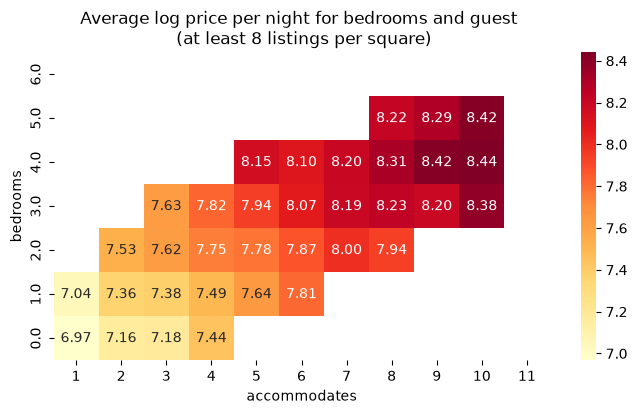

In [49]:
#look at correlation between beds/bedrooms and accomodates. Look if adding one of them differentiates the price
pivot_mean = df_c.pivot_table(index="bedrooms", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_c.pivot_table(index="bedrooms", columns="accommodates",
                                   values="price_per_night", aggfunc="count")

plt.figure(figsize=(8, 4))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 8),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
ax.set_xlim(0, 11)
ax.set_ylim(0, 7)
plt.title("Average log price per night for bedrooms and guest \n (at least 8 listings per square)")
plt.show()


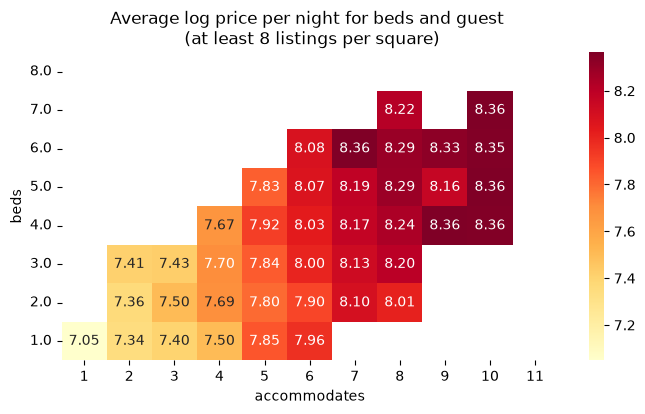

In [50]:
pivot_mean = df_c.pivot_table(index="beds", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_c.pivot_table(index="beds", columns="accommodates",
                                   values="log_price", aggfunc="count")

plt.figure(figsize=(8, 4))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 8),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
ax.set_xlim(0, 11)
ax.set_ylim(0, 8)
plt.title("Average log price per night for beds and guest \n (at least 8 listings per square)")
plt.show()

### house or apartment

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


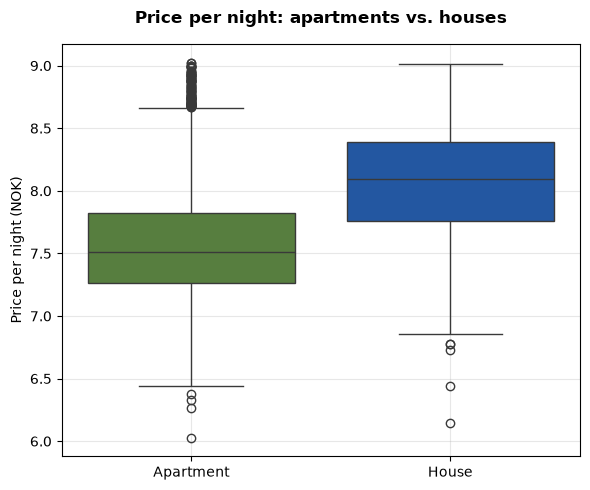

In [52]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.boxplot(data=df_c, x='is_house', y='log_price',
            hue='is_house', palette={0: cmap(2), 1: cmap(3)},
            legend=False, ax=ax)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Apartment', 'House'])
ax.set_title('Price per night: apartments vs. houses', weight='bold', pad=15)
ax.set_ylabel('Price per night (NOK)')
ax.set_xlabel('')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
### date of booking